# Deep Learning Based Stock Price Forecasting Using LSTM Networks
### Regime-dependent cross-sectional predictability in US equities

This notebook is the reproducible logic flow for the project. It benchmarks an
LSTM against classical machine learning for daily US equity return forecasting,
then reframes the task cross-sectionally and analyses where (and whether) any
signal is economically real.

**Pipeline**

```
Bloomberg export (.bas)  ─┐
                          ├─►  canonical parquet  ─►  feature panel  ─►  models  ─►  evaluation
yfinance/FRED mirror  ────┘     (source-agnostic)      (no lookahead)     (11+LSTM)   (IC, L/S, costs)
```

**Headline findings**
1. Daily return *level* prediction is a null result for every model, LSTM included.
2. A *cross-sectional* reformulation reveals significant predictability that
   concentrates in high-volatility regimes and is stronger for nonlinear models.
3. The effect is a *one-day* phenomenon: it survives neither transaction costs at
   daily frequency nor the move to a weekly horizon.

> Licensed Bloomberg data is never committed. Set `SOURCE = "yfinance"` below to
> regenerate an open mirror with an identical schema, or point at pre-built
> parquets in `data/processed/`.


## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if (ROOT / "src").exists():
    sys.path.insert(0, str(ROOT / "src"))
else:                                   # notebook run from a subfolder
    sys.path.insert(0, str(ROOT.parent / "src"))
import config as C

# Flip to True locally to retrain heavy models; default loads precomputed CSVs
RUN_HEAVY = False
SOURCE = "bloomberg"    # or "yfinance" for the open mirror
np.random.seed(C.SEED)
print("splits:", C.TRAIN_END, C.VAL_END, "| seed", C.SEED)

splits: 2021-12-31 2022-12-31 | seed 42


## 1. Data ingestion

Both sources normalise to one schema: `date, ticker, open, high, low, close,
volume`. The Bloomberg parser reads the block layout emitted by the VBA exporter
(row 5 ticker, row 6 field, row 8+ data); the mirror pulls the same fields from
yfinance with FRED for Treasury yields.

In [2]:
panel_path = C.PROC / "panel_ohlcv.parquet"
if not panel_path.exists():
    if SOURCE == "yfinance":
        from pull_yfinance import pull_equity_panel, pull_context
        pull_equity_panel(C.START_DATE); pull_context(C.START_DATE)
    else:
        from parse_bbg_csv import build as bbg_build
        bbg_build(C.RAW / "bloomberg")

px = pd.read_parquet(panel_path)
print(f"{len(px):,} rows | {px['ticker'].nunique()} tickers | "
      f"{px['date'].min().date()} -> {px['date'].max().date()}")
px.head()

2,492,653 rows | 520 tickers | 2005-01-03 -> 2026-07-06


,date,ticker,close,high,low,open,volume
0,2005-01-03,A,23.88,24.18,23.50,24.10,2234800.0
1,2005-01-04,A,23.25,23.99,23.05,23.78,2449800.0
2,2005-01-05,A,23.24,23.65,23.12,23.17,2420300.0
3,2005-01-06,A,22.73,23.44,22.69,23.40,1893000.0
4,2005-01-07,A,22.71,22.95,22.63,22.68,1669000.0


## 2. Feature engineering and the supervised panel

Every feature uses information available at the close of day $t$; the target is
the next-day log return. We build both a **level** target and a **cross-sectional**
target (next-day return demeaned across the universe each day), plus daily
percentile-rank features for the cross-sectional task. Splits are strictly
chronological.

In [3]:
from build_dataset import build
sp_path = C.PROC / "supervised_panel.parquet"
panel = build(use_context=True) if (RUN_HEAVY or not sp_path.exists()) \
        else pd.read_parquet(sp_path)

feats       = [c for c in panel.columns if c.startswith(("f_", "c_", "xr_"))]
feats_level = [c for c in panel.columns if c.startswith(("f_", "c_"))]
print(f"{len(panel):,} rows | {len(feats)} features | "
      f"splits {panel['split'].value_counts().to_dict()}")
print("high-vol day fraction:", round(panel['regime_highvol'].mean(), 3))

2,448,678 rows | 24 features | splits {'train': 1852457, 'test': 466426, 'val': 129795}
high-vol day fraction: 0.187


### 2.1 A look at the regime label
High-vol = 63-day VIX z-score > 1 (uses data through $t$ only).

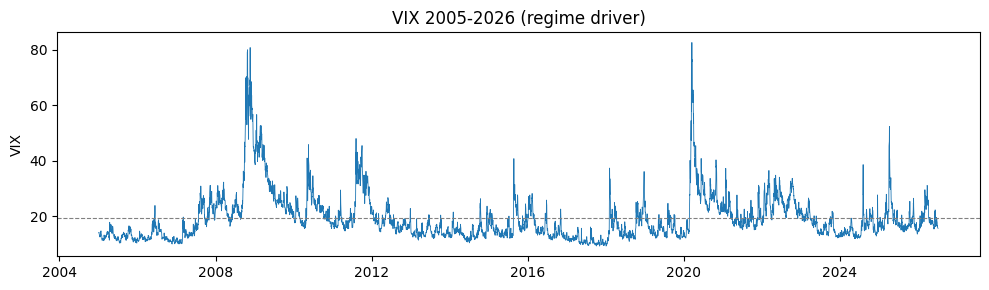

In [4]:
ctx = pd.read_parquet(C.PROC / "context.parquet")
vix = ctx[ctx.series == "VIX Index"].set_index("date")["value"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(vix.index, vix.values, lw=0.6)
ax.axhline(vix.mean(), color="grey", ls="--", lw=0.8)
ax.set_title("VIX 2005-2026 (regime driver)"); ax.set_ylabel("VIX")
plt.tight_layout(); plt.show()

## 3. Stage V1/V2: the daily-level horse race

Eleven model families predict next-day return *levels*. The naive-zero baseline is
the anchor. A shuffled-target run is included as a leakage alarm: a non-trivial IC
there would mean the pipeline leaks.

In [5]:
def daily_ic(df, pcol="y_pred", tcol="y_true"):
    ic = (df.groupby("date")
            .apply(lambda g: stats.spearmanr(g[pcol], g[tcol])[0]
                   if g[pcol].nunique() > 1 and len(g) > 4 else np.nan,
                   include_groups=False).dropna())
    t = ic.mean() / (ic.std() / np.sqrt(len(ic))) if len(ic) > 2 else np.nan
    return ic, ic.mean(), t

hr_path = C.RESULTS / "horse_race_results.csv"
if RUN_HEAVY or not hr_path.exists():
    print("Set RUN_HEAVY=True and run run_all.py for a full rebuild.")
horse = pd.read_csv(hr_path)
test = horse[horse.split == "test"].sort_values("ic_mean", ascending=False)
test[["model", "dir_acc", "ic_mean", "ic_tstat", "rmse"]].round(4)

,model,dir_acc,ic_mean,ic_tstat,rmse
15,xgboost,0.4968,0.1413,1.8316,0.0204
19,svr_linear,0.4902,0.0141,2.4204,0.0204
7,ridge,0.4906,0.0109,1.8594,0.0204
5,linear,0.4906,0.0109,1.8593,0.0204
24,lstm,0.4795,0.0042,0.7615,0.0211
22,SANITY_shuffled_ridge,0.4981,0.0039,0.6739,0.0204
21,poly2_ridge,0.4856,0.0013,0.2779,0.0204
3,naive_momentum,0.4740,-0.0152,-2.5553,0.0291
13,random_forest,0.4969,-0.0252,-0.6098,0.0210
17,lightgbm,0.4959,-0.0295,-0.6934,0.0204


**Reading it.** No model beats naive-zero on RMSE; directional accuracy sits
near 50%. The LSTM's IC (0.004, $t=0.76$) is statistically identical to the
shuffled-target control (0.004, $t=0.67$), i.e. indistinguishable from no signal.
Daily return *levels* are effectively unforecastable here. That is the correct,
expected result, not a failure.

## 4. Stage V3: cross-sectional reframing, split by regime

Instead of predicting a stock's absolute return, predict its return *relative to
the universe* (dollar-neutral). Evaluate separately on high-vol vs normal days.

In [6]:
xr_path = C.RESULTS / "xs_regime_results.csv"
if RUN_HEAVY or not xr_path.exists():
    print("Run run_xs_regime.py to (re)generate cross-sectional results.")
xs = pd.read_csv(xr_path)
xs[["model","regime","ic_mean","ic_t","ls_sharpe_gross","ls_sharpe_net","avg_turnover"]]

,model,regime,ic_mean,ic_t,ls_sharpe_gross,ls_sharpe_net,avg_turnover
0,ridge,all,0.0154,2.76,0.48,-1.99,2.03
1,ridge,highvol,0.0320,1.87,0.96,-0.69,2.12
2,ridge,normal,0.0111,2.04,0.28,-2.93,2.10
3,lightgbm,all,0.0127,2.44,0.44,-3.55,2.58
4,lightgbm,highvol,0.0436,3.17,2.09,-0.88,2.68
5,lightgbm,normal,0.0048,0.88,-0.24,-4.89,2.60


**Reading it.** Predictability is strongly regime-dependent. LightGBM reaches
IC 0.044 ($t=3.2$) on high-vol days vs 0.005 ($t=0.9$) on calm days, and the
nonlinear model overtakes linear models *only* under stress. Pooling the two
regimes dilutes the effect, which is why the level horse race looked null.

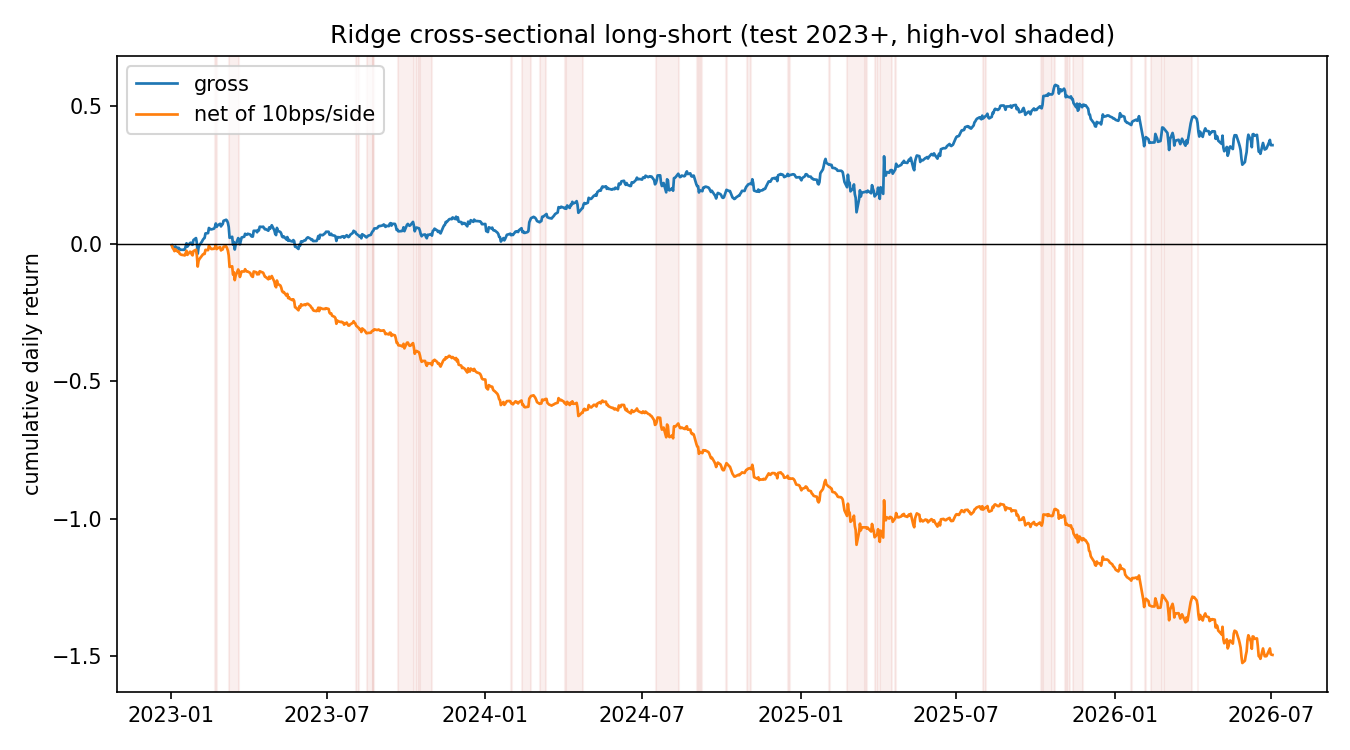

In [7]:
from IPython.display import Image, display
p = C.FIGS / "xs_ls_equity_curve.png"
if p.exists(): display(Image(str(p)))

## 5. Horizon and cost analysis: is it tradeable?

Two independent reality checks. **(a)** Transaction costs: 10 bps/side on one-way
turnover. **(b)** Horizon: retarget to 5-day returns and rebalance weekly with
non-overlapping observations (cuts trading frequency ~5x).

In [8]:
wk_path = C.RESULTS / "xs_weekly_results.csv"
if wk_path.exists():
    wk = pd.read_csv(wk_path)
    display(wk[["model","regime","n_weeks","ic_mean","ic_t","sharpe_net","avg_turnover"]])
else:
    print("Run run_xs_weekly.py to generate the weekly-rebalance results.")

,model,regime,n_weeks,ic_mean,ic_t,sharpe_net,avg_turnover
0,ridge,all,183,0.0007,0.05,-0.64,3.40
1,ridge,highvol,38,-0.0071,-0.19,-0.27,3.35
2,ridge,normal,145,0.0027,0.20,-0.74,3.42
3,lightgbm,all,0,NaN,NaN,NaN,NaN
4,lightgbm,highvol,0,NaN,NaN,NaN,NaN
5,lightgbm,normal,0,NaN,NaN,NaN,NaN


**Reading it.** The gross high-vol Sharpe (LightGBM 2.09) looks strong, but:

- **Costs kill the daily version.** ~2.6 one-way daily turnover ≈ 26 bps/day of
  cost, more than the edge, so every net Sharpe is negative.
- **The signal decays.** At a 5-day horizon the high-vol IC collapses to ≈ 0
  ($-0.007$) and the tree model degenerates to near-constant predictions. Slowing
  down removes the cost *and* the signal.

So the effect is a genuine but **short-horizon, stress-concentrated, non-tradeable**
phenomenon, consistent with short-term reversal / liquidity provision.

## 6. Conclusion

1. Daily return-level prediction is a null result across 11 models incl. LSTM.
2. Cross-sectional predictability is real and significant, concentrated in
   high-volatility regimes, stronger for nonlinear models.
3. It is a one-day effect that survives neither costs (daily) nor time (weekly).

A precisely characterised negative result, with leakage controls, chronological
evaluation and explicit cost accounting, is more credible than an unaudited
backtest that appears to succeed.

**Extensions** (see `docs/`): point-in-time membership to remove survivorship
bias; turnover-controlled execution; geographic replication (KOSPI/TAIEX/EM) as a
robustness test of the regime effect; slower fundamental signals.